<a href="https://colab.research.google.com/github/Lakshmidurga250/Spam-Mail-Detector/blob/main/Spam_Mail_Detector.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import nltk

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
import nltk

nltk.download('stopwords')
nltk.download('punkt')
nltk.download('punkt_tab')

print("NLTK resources downloaded successfully!")

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...


NLTK resources downloaded successfully!


[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


In [ ]:
!wget -O spam_dataset.zip https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip

--2026-10-05 14:36:43--  https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip
Resolving archive.ics.uci.edu (archive.ics.uci.edu)... 128.195.10.252
Connecting to archive.ics.uci.edu (archive.ics.uci.edu)|128.195.10.252|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: unspecified
Saving to: ‘spam_dataset.zip’

spam_dataset.zip        [  <=>               ] 198.65K   510KB/s    in 0.4s    

2026-10-05 14:36:44 (510 KB/s) - ‘spam_dataset.zip’ saved [203415]



In [ ]:
!unzip -o spam_dataset.zip

Archive:  spam_dataset.zip
  inflating: SMSSpamCollection       
  inflating: readme                  


In [ ]:
import pandas as pd

df = pd.read_csv(
    "SMSSpamCollection",
    sep="\t",
    header=None,
    names=["label", "message"]
)

print("Dataset loaded successfully!")

display(df.head())

Dataset loaded successfully!


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [ ]:
# Check dataset information

print("Dataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nClass Distribution:")
print(df["label"].value_counts())

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape:
(5572, 2)

Column Names:
['label', 'message']

Class Distribution:
label
ham     4825
spam     747
Name: count, dtype: int64

Missing Values:
label      0
message    0
dtype: int64


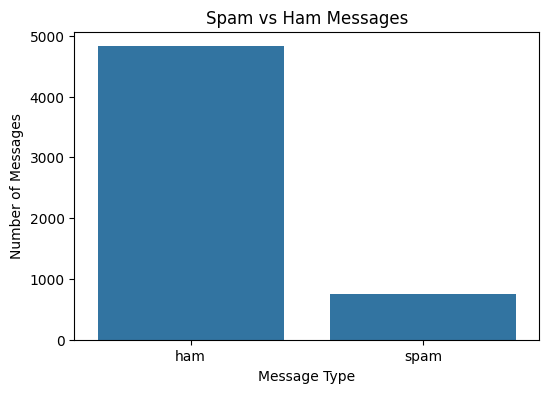

In [ ]:
# Visualize spam and ham messages

plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="label")

plt.title("Spam vs Ham Messages")
plt.xlabel("Message Type")
plt.ylabel("Number of Messages")

plt.show()

In [ ]:
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
import string

In [ ]:
# Text preprocessing function

stop_words = set(stopwords.words("english"))

def preprocess_text(text):
    # Convert text to lowercase
    text = text.lower()

    # Tokenize the text
    words = word_tokenize(text)

    # Remove punctuation and stopwords
    words = [
        word for word in words
        if word.isalnum() and word not in stop_words
    ]

    # Join words back into a sentence
    return " ".join(words)

In [ ]:
# Apply preprocessing to all messages

df["clean_message"] = df["message"].apply(preprocess_text)

display(df[["message", "clean_message"]].head())

,message,clean_message
0,"Go until jurong point, crazy.. Available only ...",go jurong point crazy available bugis n great ...
1,Ok lar... Joking wif u oni...,ok lar joking wif u oni
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entry 2 wkly comp win fa cup final tkts 2...
3,U dun say so early hor... U c already then say...,u dun say early hor u c already say
4,"Nah I don't think he goes to usf, he lives aro...",nah think goes usf lives around though


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Create TF-IDF vectorizer
tfidf = TfidfVectorizer()

# Convert text into numerical features
X = tfidf.fit_transform(df["clean_message"])

# Target labels
y = df["label"]

print("TF-IDF feature extraction completed!")
print("Feature matrix shape:", X.shape)

TF-IDF feature extraction completed!
Feature matrix shape: (5572, 8079)


In [ ]:
# Split data into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 4457
Testing samples: 1115


In [ ]:
from sklearn.naive_bayes import MultinomialNB

# Create Naive Bayes classifier
model = MultinomialNB()

# Train the model
model.fit(X_train, y_train)

print("Naive Bayes model trained successfully!")

Naive Bayes model trained successfully!


In [ ]:
# Predict labels for test messages

y_pred = model.predict(X_test)

print("Predictions completed!")
print(y_pred[:20])

Predictions completed!
['ham' 'ham' 'ham' 'spam' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham'
 'ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham']


In [ ]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("Accuracy Percentage:", accuracy * 100, "%")

Accuracy: 0.9641255605381166
Accuracy Percentage: 96.41255605381166 %


In [ ]:
from sklearn.metrics import classification_report

print("Classification Report:")
print(classification_report(y_test, y_pred))

Classification Report:
              precision    recall  f1-score   support

         ham       0.96      1.00      0.98       966
        spam       1.00      0.73      0.84       149

    accuracy                           0.96      1115
   macro avg       0.98      0.87      0.91      1115
weighted avg       0.97      0.96      0.96      1115



In [ ]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[966   0]
 [ 40 109]]


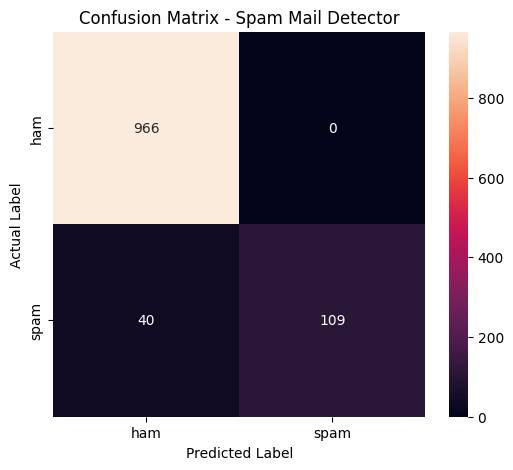

In [ ]:
plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=["ham", "spam"],
    yticklabels=["ham", "spam"]
)

plt.title("Confusion Matrix - Spam Mail Detector")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.show()